In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [10]:
data = pd.read_csv('./DataSets/Salary_Data.csv')
data

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [11]:
X = data[['YearsExperience']]
X

,YearsExperience
0,1.1
1,1.3
2,1.5
3,2.0
4,2.2
5,2.9
6,3.0
7,3.2
8,3.2
9,3.7


In [12]:
y = data['Salary']
y

0      39343.0
1      46205.0
2      37731.0
3      43525.0
4      39891.0
5      56642.0
6      60150.0
7      54445.0
8      64445.0
9      57189.0
10     63218.0
11     55794.0
12     56957.0
13     57081.0
14     61111.0
15     67938.0
16     66029.0
17     83088.0
18     81363.0
19     93940.0
20     91738.0
21     98273.0
22    101302.0
23    113812.0
24    109431.0
25    105582.0
26    116969.0
27    112635.0
28    122391.0
29    121872.0
Name: Salary, dtype: float64

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [15]:
print('Intercept: ', model.intercept_)
print('Slope: ', model.coef_[0])
print('Actual Values: ', y_test.values)
print('Predicted Values: ', y_pred)

Intercept:  25321.583011776813
Slope:  9423.815323030976
Actual Values:  [112635.  67938. 113812.  83088.  64445.  57189.]
Predicted Values:  [115790.21011287  71498.27809463 102596.86866063  75267.80422384
  55477.79204548  60189.69970699]


In [17]:
print('MAE: ', mean_absolute_error(y_test, y_pred))
print('MSE: ', mean_squared_error(y_test, y_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R-Squared Error: ', r2_score(y_test, y_pred))

MAE:  6286.453830757749
MSE:  49830096.85590839
RMSE:  7059.04362190151
R-Squared Error:  0.9024461774180497


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


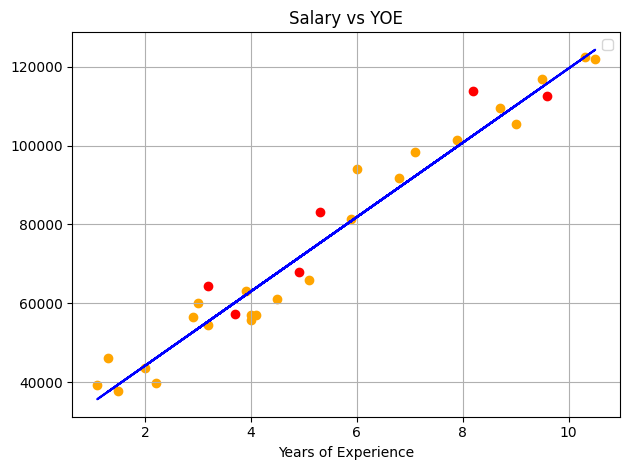

In [18]:
plt.scatter(X_train, y_train, color='orange')
plt.scatter(X_test, y_test, color='red')

plt.plot(X_train, model.predict(X_train), color='blue')

plt.title('Salary vs YOE')

plt.legend()
plt.xlabel('Salary')
plt.xlabel('Years of Experience')


plt.tight_layout()
plt.grid()
plt.show()

In [19]:
# plt.scatter(X_test, y_test, color='blue', label='Actual Data')
# plt.plot(X_test, y_pred, color='red', label='Regression Line')

# plt.title('Salary vs YOE')

# plt.legend()
# plt.xlabel('Salary')
# plt.xlabel('Years of Experience')


# plt.tight_layout()
# plt.grid()
# plt.show()

In [20]:
experience = np.array([[7.5]])
predicted_salary = model.predict(experience)

print(f'The predicted salary for 7.5 YOE is {predicted_salary[0]:.2f}')

The predicted salary for 7.5 YOE is 96000.20


c:\Users\athre\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


### Ridge

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

In [22]:
# Create a pipeline
# 1. Standardize the predictors
# 2. Apply Ridge Regression

In [20]:
model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()), ('ridge', Ridge())])

In [21]:
y_pred = model.predict(X_test)
y_pred

array([114126.90670836,  71606.65197084, 101461.29891421,  75225.39705489,
        56226.98536366,  60750.41671871])

In [33]:
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [24]:
model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=[0.01, 0.1, 1, 10, 100])
)

In [25]:
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('ridgecv', RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]))])

In [26]:
ridge_model = model.named_steps['ridgecv']
print('Best alpha (lambda): ', ridge_model.alpha_)

Best alpha (lambda):  0.1


In [27]:
y_pred = model.predict(X_test)
y_pred

array([115617.66826593,  71509.52019797, 102479.07096909,  75263.40513992,
        55555.50919467,  60247.86537211])

In [28]:
print('Intercept: ', ridge_model.intercept_)
print('Slope: ', ridge_model.coef_[0])
print('Actual Values: ', y_test.values)
print('Predicted Values: ', y_pred)

Intercept:  74207.625
Slope:  27038.875444811478
Actual Values:  [112635.  67938. 113812.  83088.  64445.  57189.]
Predicted Values:  [115617.66826593  71509.52019797 102479.07096909  75263.40513992
  55555.50919467  60247.86537211]


In [29]:
print('MAE: ', mean_absolute_error(y_test, y_pred))
print('MSE: ', mean_squared_error(y_test, y_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R-Squared Error: ', r2_score(y_test, y_pred))

MAE:  6276.678088721218
MSE:  49948555.96597323
RMSE:  7067.429233177593
R-Squared Error:  0.9022142665903445


### Lasso

In [39]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

In [ ]:
# Create a pipeline
# 1. Standardize the predictors
# 2. Apply Lasso Regression

In [38]:
model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=1.0)
)

model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()), ('lasso', Lasso())])

In [40]:
y_pred = model.predict(X_test)
y_pred

array([115788.67861267,  71498.37788076, 102595.82307551,  75267.76517709,
        55478.48187135,  60190.21599176])

In [42]:
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [43]:
model = make_pipeline(
    StandardScaler(),
    LassoCV(alphas=[0.01, 0.1, 1, 10, 100])
)

In [44]:
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('lassocv', LassoCV(alphas=[0.01, 0.1, 1, 10, 100]))])

In [47]:
lasso_model = model.named_steps['lassocv']
print('Best alpha (lambda): ', lasso_model.alpha_)

Best alpha (lambda):  100.0


In [48]:
y_pred = model.predict(X_test)
y_pred

array([115637.06009245,  71508.25670786, 102492.3101481 ,  75263.8995491 ,
        55546.77463258,  60241.32818413])

In [49]:
print('Intercept: ', ridge_model.intercept_)
print('Slope: ', ridge_model.coef_[0])
print('Actual Values: ', y_test.values)
print('Predicted Values: ', y_pred)

Intercept:  74207.625
Slope:  27051.53742583368
Actual Values:  [112635.  67938. 113812.  83088.  64445.  57189.]
Predicted Values:  [115637.06009245  71508.25670786 102492.3101481   75263.8995491
  55546.77463258  60241.32818413]


In [50]:
print('MAE: ', mean_absolute_error(y_test, y_pred))
print('MSE: ', mean_squared_error(y_test, y_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R-Squared Error: ', r2_score(y_test, y_pred))

MAE:  6277.776775776263
MSE:  49934357.66677525
RMSE:  7066.424673537194
R-Squared Error:  0.9022420630115502
